# Powering the Planet

This project compares France, Germany, and Italy using energy and CO₂ data from Our World in Data.

Questions:
1. How did fossil-fuel and renewable-energy shares change from 2000 to 2025?
2. How did total and per-person CO₂ emissions change from 2000 to 2024?
3. When did GDP rise while CO₂ emissions fell from 2000 to 2022?


## 1. Energy shares (2000–2025)

We compare the fossil-fuel and renewable-energy shares reported in the OWID energy data for France, Germany, and Italy. Each share is a percentage. Subtracting the 2000 share from the 2025 share gives a change in percentage points.

In [1]:
from powering_the_planet.data import load_energy

energy = load_energy()
print(energy.shape)

(19494, 130)


In [2]:
from powering_the_planet.analysis import select_energy_mix

energy_mix = select_energy_mix(energy)
print(energy_mix.shape)
energy_mix.groupby("country")["year"].agg(["min", "max", "count"])

(78, 4)


,min,max,count
country,,,
France,2000,2025,26
Germany,2000,2025,26
Italy,2000,2025,26


In [3]:
from powering_the_planet.analysis import energy_share_changes

energy_changes = energy_share_changes(energy_mix)
energy_changes.round(2)

,fossil_fuels_energy_share_pct,renewables_energy_share_pct
country,,
France,-11.79,5.65
Germany,-0.97,13.97
Italy,-10.71,10.71


From 2000 to 2025, the fossil-fuel share fell by 11.79 percentage points in France, 0.97 in Germany, and 10.71 in Italy. The renewable-energy share rose by 5.65, 13.97, and 10.71 points, respectively. Germany had the largest increase in renewable share. These figures describe shares of energy, not changes in the total amount of energy used.

## 2. CO₂ emissions (2000–2024)

We compare annual CO₂ emissions and emissions per person for France, Germany, and Italy. For each measure, percentage change is calculated as (2024 value − 2000 value) ÷ 2000 value × 100.

In [4]:
from powering_the_planet.data import load_co2

co2 = load_co2()
print(co2.shape)

(50411, 79)


In [5]:
from powering_the_planet.analysis import select_co2

co2_focus = select_co2(co2)
print(co2_focus.shape)
co2_focus.groupby("country")["year"].agg(["min", "max", "count"])

(75, 4)


,min,max,count
country,,,
France,2000,2024,25
Germany,2000,2024,25
Italy,2000,2024,25


In [6]:
from powering_the_planet.analysis import co2_percent_changes

co2_changes = co2_percent_changes(co2_focus)
co2_changes.round(2)

,co2,co2_per_capita
country,,
France,-35.17,-42.05
Germany,-36.34,-38.41
Italy,-35.70,-37.95


From 2000 to 2024, annual CO₂ emissions fell by 35.17% in France, 36.34% in Germany, and 35.70% in Italy. Emissions per person also fell: by 42.05%, 38.41%, and 37.95%, respectively. Germany had the largest percentage decline in total emissions, while France had the largest decline per person. These numbers compare the two endpoint years.

## 3. GDP and CO₂ (2000–2022)

We use the GDP and CO₂ columns in the OWID CO₂ data. First, we compare 2022 with 2000 for each country. Then we compare each year with the preceding year to find when GDP rose while CO₂ emissions fell.

In [7]:
from powering_the_planet.analysis import select_gdp_co2

gdp_co2 = select_gdp_co2(co2)
print(gdp_co2.shape)
gdp_co2.groupby("country")["year"].agg(["min", "max", "count"])

(69, 4)


,min,max,count
country,,,
France,2000,2022,23
Germany,2000,2022,23
Italy,2000,2022,23


In [8]:
gdp_co2[["gdp", "co2"]].isna().sum()

gdp    0
co2    0
dtype: int64

In [9]:
from powering_the_planet.analysis import gdp_co2_percent_changes

changes = gdp_co2_percent_changes(gdp_co2)
changes

,gdp,co2
country,,
France,31.495806,-27.522964
Germany,43.811875,-25.710678
Italy,14.608050,-27.573260


From 2000 to 2022, GDP increased in France (31.5%), Germany (43.8%), and Italy (14.6%), while annual CO₂ emissions decreased by 27.5%, 25.7%, and 27.6%, respectively. These figures compare the two endpoint years; they do not show what happened in each year between them.

In [10]:
from powering_the_planet.analysis import years_gdp_up_co2_down

matching_years = years_gdp_up_co2_down(gdp_co2)
print(matching_years.shape)
matching_years

(28, 4)


,country,year,gdp_change_pct,co2_change_pct
17361,France,2002,1.421217,-1.109124
17365,France,2006,2.600851,-2.323539
17366,France,2007,2.509949,-2.510115
17367,France,2008,0.330397,-1.681597
17370,France,2011,2.173390,-5.821740
17373,France,2014,0.956178,-8.945380
17377,France,2018,1.865066,-4.511756
17378,France,2019,1.842976,-2.098689
17381,France,2022,2.562398,-3.894939
18297,Germany,2002,1.040631,-1.794086


The year-by-year comparison found 28 country-year cases where GDP increased while CO₂ emissions decreased from the preceding year: 9 in France, 12 in Germany, and 7 in Italy. All three countries met this condition in 2007, 2011, 2018, and 2019. This comparison shows what changed in those years; it does not explain why emissions fell.

## 4. Trends over time

The comparisons above show the change between the first and last years. The charts below show what happened between those years. In the GDP–CO₂ charts, both measures are set to 100 in 2000, making their relative changes comparable despite their different units.

<Axes: title={'center': 'Fossil-fuel share of total energy, 2000–2025'}, xlabel='Year', ylabel='Share of total energy (%)'>

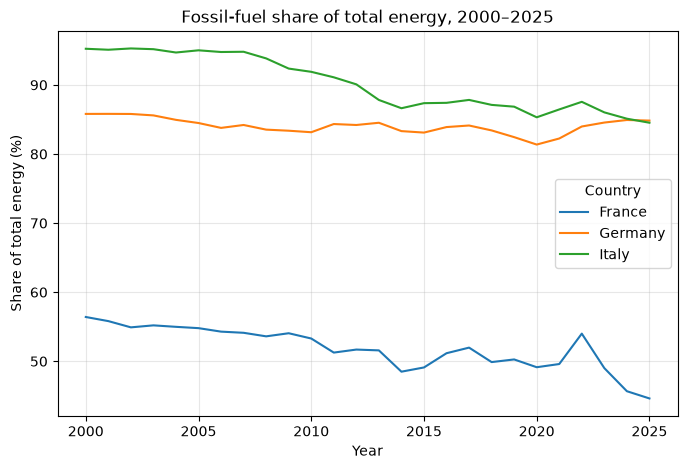

In [11]:
from powering_the_planet.plots import plot_energy_share

plot_energy_share(
    energy_mix,
    "fossil_fuels_energy_share_pct",
    "Fossil-fuel share of total energy, 2000–2025",
)

<Axes: title={'center': 'Renewable-energy share of total energy, 2000–2025'}, xlabel='Year', ylabel='Share of total energy (%)'>

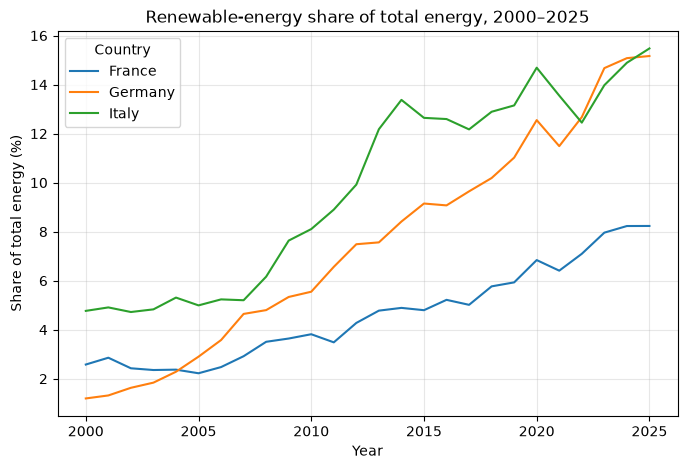

In [12]:
plot_energy_share(
    energy_mix,
    "renewables_energy_share_pct",
    "Renewable-energy share of total energy, 2000–2025",
)

<Axes: title={'center': 'Annual CO₂ emissions, 2000–2024'}, xlabel='Year', ylabel='Million tonnes of CO₂'>

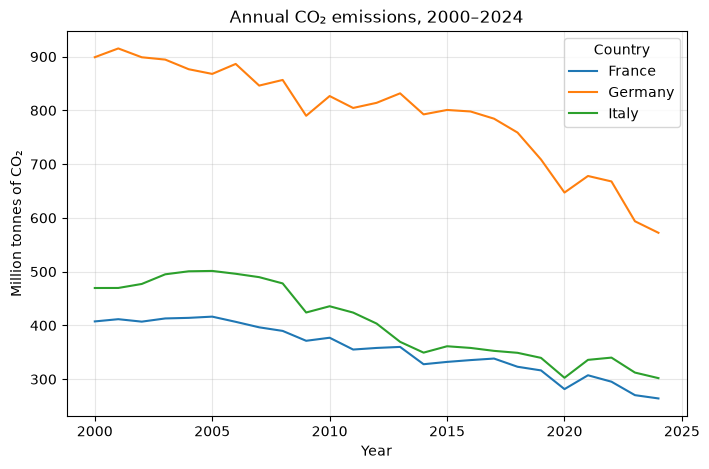

In [13]:
from powering_the_planet.plots import plot_co2

plot_co2(
    co2_focus,
    "co2",
    "Annual CO₂ emissions, 2000–2024",
    "Million tonnes of CO₂",
)

<Axes: title={'center': 'Annual CO₂ emissions per person, 2000–2024'}, xlabel='Year', ylabel='Tonnes of CO₂ per person'>

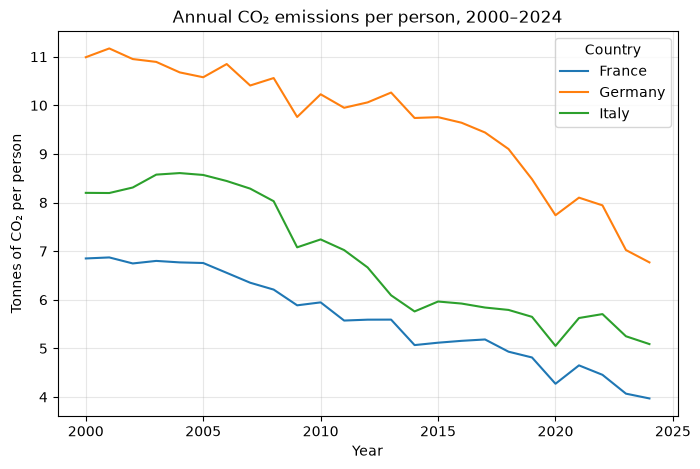

In [14]:
plot_co2(
    co2_focus,
    "co2_per_capita",
    "Annual CO₂ emissions per person, 2000–2024",
    "Tonnes of CO₂ per person",
)

<Axes: title={'center': 'France: GDP and CO₂ (2000 = 100)'}, xlabel='Year', ylabel='Index (2000 = 100)'>

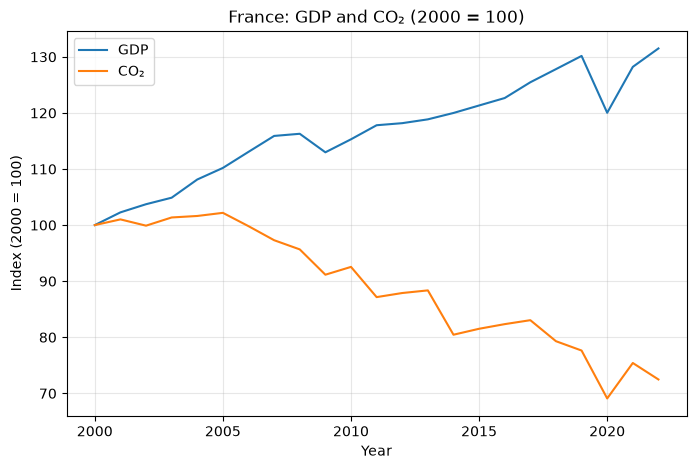

In [15]:
from powering_the_planet.plots import plot_gdp_co2_indexed

plot_gdp_co2_indexed(gdp_co2, "France")

<Axes: title={'center': 'Germany: GDP and CO₂ (2000 = 100)'}, xlabel='Year', ylabel='Index (2000 = 100)'>

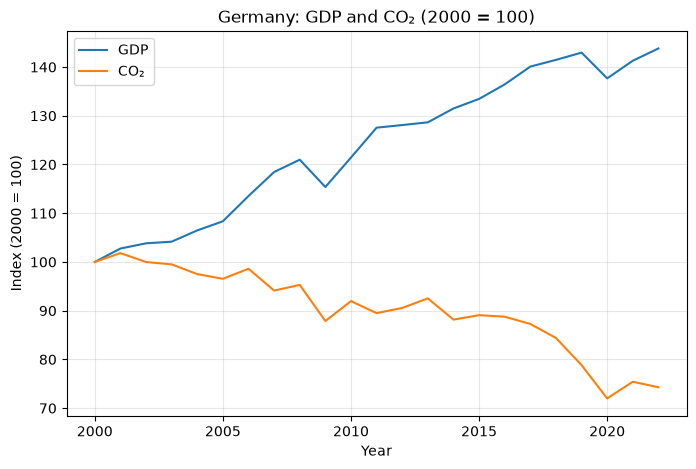

In [16]:
plot_gdp_co2_indexed(gdp_co2, "Germany")

<Axes: title={'center': 'Italy: GDP and CO₂ (2000 = 100)'}, xlabel='Year', ylabel='Index (2000 = 100)'>

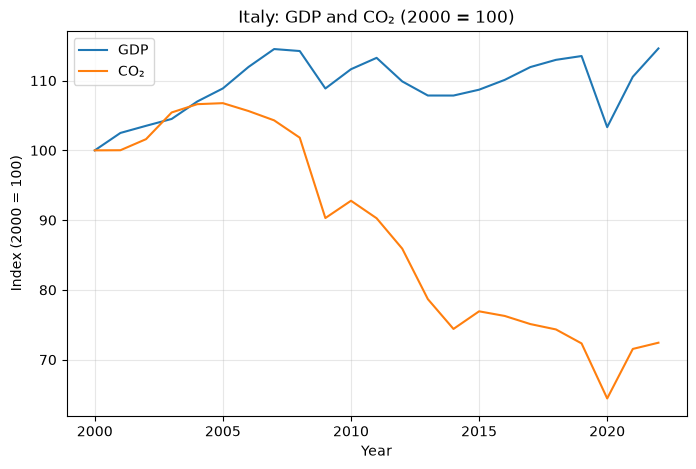

In [17]:
plot_gdp_co2_indexed(gdp_co2, "Italy")

## 5. Conclusion

In France, Germany, and Italy, the fossil-fuel share fell and the renewable-energy share rose from 2000 to 2025. Annual CO₂ emissions and emissions per person were lower in 2024 than in 2000. GDP was higher and annual CO₂ emissions lower in 2022 than in 2000 in all three countries.

The year-by-year comparison found 28 country-year cases where GDP rose while CO₂ fell compared with the preceding year. These results describe the selected countries and periods; they do not show what caused the changes. The three analyses use different end years, so their changes do not cover the same length of time.

## 6. Data sources and scope

The energy figures come from [Our World in Data's energy dataset](https://catalog.ourworldindata.org/energy/owid_energy/). The fossil-fuel and renewable-energy shares are percentages of total energy supply.

The CO₂ and GDP figures come from [Our World in Data's CO₂ dataset](https://github.com/owid/co2-data). Here, annual CO₂ emissions cover fossil fuels and industry; land-use change is excluded. “Total” means the countrywide amount, while “per person” divides it by population.

The report uses local copies of the CSV files. They are excluded from Git; the README explains how to download them. OWID may update the files, so a later download may produce different numbers.